<a href="https://colab.research.google.com/github/Anyangos/Digital-Twin/blob/probability-and-neural-networks/01_probability_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.1: Probability & Neural Networks for Digital Twins

## Learning Objectives
- Understand how AI makes predictions using probability
- Learn the basics of neural networks
- Apply these concepts to building a digital twin

## Digital Twin Context
A **digital twin** is a virtual representation of a physical entity (person, object, system). In this series, we'll build a digital twin that can:
- Predict behaviors and preferences
- Understand and respond to language
- Learn from interactions

## Key Insight
> "AI isn't thinking; it's predicting the next number."

This applies to everything from weather prediction to language generation!

---
## Part 1: Probability Foundations

Let's start with the basics: How does AI make predictions?

In [6]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


### 1.1 Simple Prediction: Next Number

Let's simulate a digital twin predicting your next action based on historical data.

Activity Probabilities:
  Sleep: 20.00%
  Work: 40.00%
  Exercise: 13.33%
  Social: 13.33%
  Leisure: 13.33%


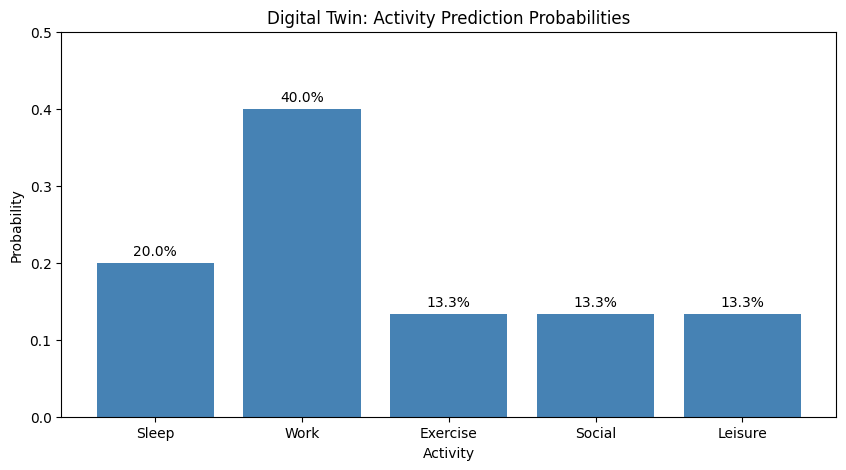

In [7]:
from collections import Counter
import matplotlib.pyplot as plt

# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure

historical_activities = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]

def calculate_probabilities(sequence):
    """
    Calculate probability distribution from a sequence.

    Args:
        sequence: List of integers representing activities

    Returns:
        dict: Probability of each activity
    """
    counts = Counter(sequence)
    total = len(sequence)
    probabilities = {activity: count/total for activity, count in counts.items()}
    return probabilities

# Calculate probabilities
probs = calculate_probabilities(historical_activities)

# Display results
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}
print("Activity Probabilities:")
for activity, prob in sorted(probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# Visualize
plt.figure(figsize=(10, 5))
activities = [activity_names[k] for k in sorted(probs.keys())]
probabilities = [probs[k] for k in sorted(probs.keys())]
plt.bar(activities, probabilities, color='steelblue')
plt.title('Digital Twin: Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.5)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.show()

### 🎯 Exercise 1.1 (Easy): Understanding Probabilities

**Task**: Modify the historical activities to represent your own daily routine for 2 weeks (14 days).

**Questions**:
1. Which activity has the highest probability?
2. What does this tell you about the pattern in your data?
3. How would adding more data points affect the predictions?

In [ ]:
# YOUR CODE HERE
# Create your own sequence of activities (14 values)
my_activities = [0, 1, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 4]  # Replace with your pattern

# Calculate and visualize
my_probs = calculate_probabilities(my_activities)

# YOUR ANALYSIS HERE (write answers as comments)
# 1. Highest probability activity:
# 2. Pattern insight:
# 3. Impact of more data:

### 1.2 Conditional Probability: Context Matters

What if predictions depend on previous activities? This is where context comes in!

In [8]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]

        if current not in transitions:
            transitions[current] = []
        transitions[current].append(next_activity)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Conditional Probabilities: P(Next | Current)

After Sleep:
  → Work: 100.00%

After Work:
  → Exercise: 33.33%
  → Social: 33.33%
  → Leisure: 33.33%

After Exercise:
  → Work: 100.00%

After Social:
  → Work: 100.00%

After Leisure:
  → Sleep: 100.00%



### 🎯 Exercise 1.2 (Intermediate): Markov Chain Prediction

**Task**: Build a simple predictor that uses conditional probabilities to predict the next activity.

**Challenge**: What happens after "Work"? Which activity is most likely?

In [9]:
def predict_next_activity(current_activity, conditional_probs):
    """
    Predict the most likely next activity.

    Args:
        current_activity: Current activity code
        conditional_probs: Dictionary of conditional probabilities

    Returns:
        int: Most likely next activity
    """
    # YOUR CODE HERE
    # Hint: Find the activity with maximum probability given current_activity
    if current_activity not in conditional_probs:
        return None

    next_probs = conditional_probs[current_activity]
    # Complete this function

    pass

# Test your function
current = 1  # Work
predicted = predict_next_activity(current, cond_probs)
print(f"After {activity_names[current]}, most likely next: {activity_names.get(predicted, 'Unknown')}")

# BONUS: Predict a sequence of 5 activities starting from "Work"

After Work, most likely next: Unknown


---
## Part 2: Neural Networks Basics

Now let's see how neural networks learn to make predictions!

### 2.1 The Perceptron: Building Block of Neural Networks

A perceptron is the simplest neural network - it takes inputs, applies weights, and produces an output.

In [10]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):
    """
    Simple perceptron implementation.

    Args:
        inputs: Array of input values
        weights: Array of weights
        bias: Bias term

    Returns:
        float: Output after activation
    """
    # Calculate weighted sum
    weighted_sum = np.dot(inputs, weights) + bias
    # Apply activation function
    output = sigmoid(weighted_sum)
    return output

# Example: Predicting if someone will exercise based on features
# Features: [hours_of_sleep, free_time_hours, energy_level (0-1)]
person_features = np.array([7, 2, 0.8])  # 7 hours sleep, 2 hours free time, high energy

# Initialize random weights
weights = np.array([0.3, 0.5, 0.7])
bias = -0.5

prediction = perceptron(person_features, weights, bias)
print(f"Probability of exercising: {prediction:.2%}")
print(f"Prediction: {'Will exercise' if prediction > 0.5 else 'Will not exercise'}")

Probability of exercising: 95.93%
Prediction: Will exercise


### 🎯 Exercise 2.1 (Easy): Feature Engineering

**Task**: Modify the features and observe how the prediction changes.

**Questions**:
1. What happens when sleep hours decrease to 4?
2. What if free time increases to 4 hours?
3. Which feature seems to have the most impact based on the weights?

In [11]:
# YOUR CODE HERE
# Test different feature combinations

test_cases = [
    np.array([4, 2, 0.8]),  # Low sleep
    np.array([7, 4, 0.8]),  # More free time
    np.array([7, 2, 0.3]),  # Low energy
]

# Test each case and analyze results


### 2.2 Training a Simple Neural Network





Let's see how a network learns by adjusting weights!

In [12]:
class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

        # Store training history
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass - update weights."""
        m = X.shape[0]

        # Calculate gradients
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the network."""
        for epoch in range(epochs):
            # Forward pass
            output = self.forward(X)

            # Calculate loss
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            # Backward pass
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        """Make predictions."""
        return self.forward(X)

# Create training data for digital twin
# Features: [day_of_week (0-6), time_of_day (0-23), weather (0-1), mood (0-1)]
# Target: [probability of social activity]

np.random.seed(42)
X_train = np.random.rand(100, 4)
# Simulate pattern: social activity more likely on weekends (day > 5) and good weather
y_train = ((X_train[:, 0] > 0.7) & (X_train[:, 2] > 0.5)).astype(float).reshape(-1, 1)
y_train += np.random.rand(100, 1) * 0.2  # Add noise
y_train = np.clip(y_train, 0, 1)

# Create and train network
nn = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=1)
print("Training neural network...\n")
nn.train(X_train, y_train, epochs=500, learning_rate=0.5)

Training neural network...

Epoch 0, Loss: 0.5069
Epoch 100, Loss: 0.1061
Epoch 200, Loss: 0.0863
Epoch 300, Loss: 0.0678
Epoch 400, Loss: 0.0550


In [ ]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('Neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss: {nn.loss_history[-1]:.4f}")

### 🎯 Exercise 2.2 (Intermediate): Digital Twin Prediction

**Task**: Test the trained network on new scenarios and interpret results.

**Scenarios to test**:
1. Weekend evening (day=6, time=18, weather=0.8, mood=0.9)
2. Weekday morning (day=2, time=8, weather=0.3, mood=0.5)
3. Weekend with bad weather (day=5, time=14, weather=0.2, mood=0.6)

In [13]:
# YOUR CODE HERE
# Normalize inputs (scale to 0-1 range)
def normalize_input(day, time, weather, mood):
    return np.array([[day/7, time/24, weather, mood]])

# Test scenarios
scenarios = [
    ("Weekend evening, good weather", 6, 18, 0.8, 0.9),
    ("Weekday morning, poor weather", 2, 8, 0.3, 0.5),
    ("Weekend afternoon, bad weather", 5, 14, 0.2, 0.6),
]

# Make predictions and analyze
for name, day, time, weather, mood in scenarios:
    X_test = normalize_input(day, time, weather, mood)
    prediction = nn.predict(X_test)
    print(f"{name}")
    print(f"  Social activity probability: {prediction[0][0]:.2%}\n")

Weekend evening, good weather
  Social activity probability: 72.61%

Weekday morning, poor weather
  Social activity probability: 6.27%

Weekend afternoon, bad weather
  Social activity probability: 22.70%



### 🎯 Exercise 2.3 (Advanced): Improve the Digital Twin

**Task**: Enhance the neural network to make better predictions.

**Challenges**:
1. Add more training data with realistic patterns
2. Experiment with different network architectures (hidden layer size)
3. Try different learning rates
4. Add a second hidden layer
5. Create a visualization showing prediction accuracy


(500, 4) (500, 1) 0.0 0.9759125881857288


(400, 4) (400, 1)
Baseline, (always guess the average): 0.0348

Epoch 0, Loss: 0.0609
Epoch 100, Loss: 0.0384
Epoch 200, Loss: 0.0337
Epoch 300, Loss: 0.0277
Epoch 400, Loss: 0.0214
(4, 4, 1) train0.01643 | test0.01362

Epoch 0, Loss: 0.0437
Epoch 100, Loss: 0.0345
Epoch 200, Loss: 0.0262
Epoch 300, Loss: 0.0192
Epoch 400, Loss: 0.0149
(4, 8, 1) train0.01277 | test0.01113

Epoch 0, Loss: 0.0570
Epoch 100, Loss: 0.0290
Epoch 200, Loss: 0.0196
Epoch 300, Loss: 0.0145
Epoch 400, Loss: 0.0124
(4, 16, 1) train0.01172 | test0.01067

Learning rates
Epoch 0, Loss: 0.0437
Epoch 100, Loss: 0.0432
Epoch 200, Loss: 0.0430
Epoch 300, Loss: 0.0428
Epoch 400, Loss: 0.0426
0.01 test 0.03637

Epoch 0, Loss: 0.0437
Epoch 100, Loss: 0.0415
Epoch 200, Loss: 0.0396
Epoch 300, Loss: 0.0379
Epoch 400, Loss: 0.0362
0.1 test 0.02959

Epoch 0, Loss: 0.0437
Epoch 100, Loss: 0.0345
Epoch 200, Loss: 0.0262
Epoch 300, Loss: 0.0192
Epoch 400, Loss: 0.0149
0.5 test 0.01113


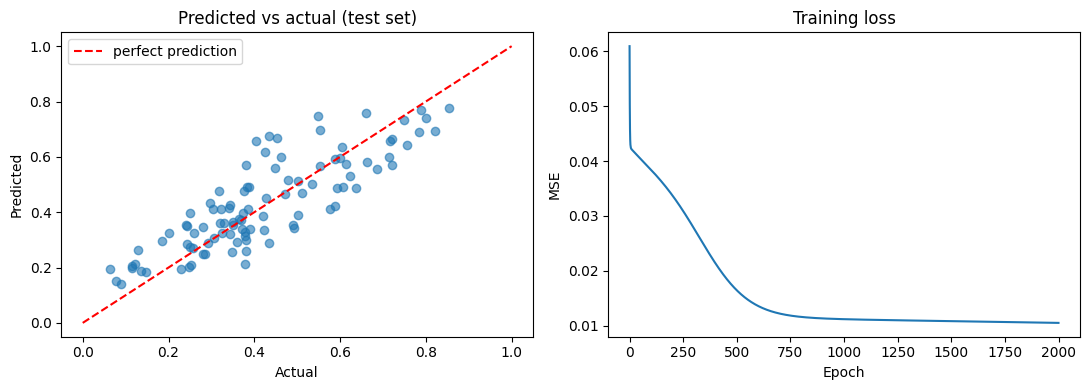

this (4, 8, 1) plot
Epoch 0, Loss: 0.0437
Epoch 100, Loss: 0.0345
Epoch 200, Loss: 0.0262
Epoch 300, Loss: 0.0192
Epoch 400, Loss: 0.0149
Epoch 500, Loss: 0.0128
Epoch 600, Loss: 0.0119
Epoch 700, Loss: 0.0116
Epoch 800, Loss: 0.0114
Epoch 900, Loss: 0.0114
Epoch 1000, Loss: 0.0113
Epoch 1100, Loss: 0.0113
Epoch 1200, Loss: 0.0113
Epoch 1300, Loss: 0.0112
Epoch 1400, Loss: 0.0112
Epoch 1500, Loss: 0.0112
Epoch 1600, Loss: 0.0112
Epoch 1700, Loss: 0.0111
Epoch 1800, Loss: 0.0111
Epoch 1900, Loss: 0.0111


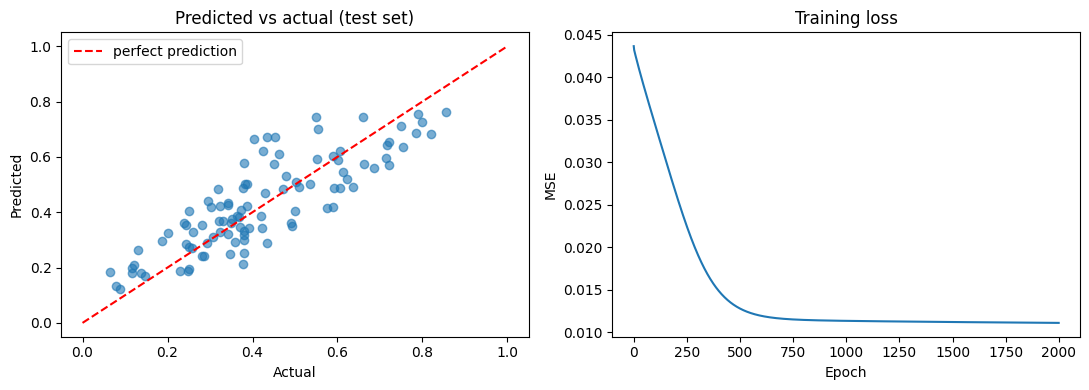

this (4, 16, 1) plot
Epoch 0, Loss: 0.0570
Epoch 100, Loss: 0.0290
Epoch 200, Loss: 0.0196
Epoch 300, Loss: 0.0145
Epoch 400, Loss: 0.0124
Epoch 500, Loss: 0.0117
Epoch 600, Loss: 0.0115
Epoch 700, Loss: 0.0114
Epoch 800, Loss: 0.0113
Epoch 900, Loss: 0.0113
Epoch 1000, Loss: 0.0112
Epoch 1100, Loss: 0.0112
Epoch 1200, Loss: 0.0111
Epoch 1300, Loss: 0.0111
Epoch 1400, Loss: 0.0111
Epoch 1500, Loss: 0.0111
Epoch 1600, Loss: 0.0110
Epoch 1700, Loss: 0.0110
Epoch 1800, Loss: 0.0110
Epoch 1900, Loss: 0.0109


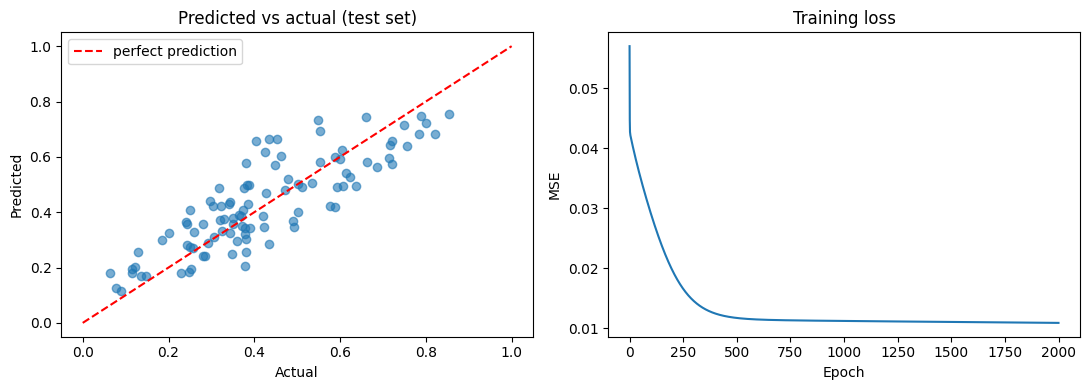

In [14]:
# YOUR CODE HERE
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
  return 1/(1 + np.exp(-x))

# Challenge: Create a better training dataset

def generate_realistic_data(n_samples=500):
    """
    Generate more realistic training data for digital twin.

    Pattern rules:
    - Social activity higher on weekends
    - Time of day matters (evening > morning)
    - Good weather increases probability
    - Good mood increases probability
    """
    # YOUR CODE HERE
    X = np.random.rand(n_samples, 4)
    day, time, weather, mood = X[:, 0], X[:, 1], X[:, 2], X[:, 3]

    is_weekend = (day >= 5/7).astype(float)
    score = 0.35 * is_weekend + 0.20 * time + 0.25 * weather + 0.20 * mood
    score += np.random.normal(0, 0.05, n_samples)

    y = np.clip(score, 0, 1).reshape(-1, 1)
    return X, y

print()

np.random.seed(42)
X, y = generate_realistic_data(500)
print(X.shape, y.shape, y.min(), y.max())
print()

def split_data(X, y, test_fraction=0.2):
  n = X.shape[0]
  cut = int(round(n * (1-test_fraction)))
  return X[:cut], y[:cut], X[cut:], y[cut:]
print()

X_train, y_train, X_test, y_test = split_data(X, y)
print(X_train.shape, y_train.shape)

def train_model(arch, X_train, y_train, learning_rate, epochs=500, seed=0):
  np.random.seed(seed)
  model = SimpleNeuralNetwork(*arch)
  model.train(X_train, y_train, epochs=epochs, learning_rate=learning_rate)
  return model

def evaluate(model, X, y):
  return np.mean((model.predict(X) - y) ** 2)

baseline = np.mean((y_train.mean() - y_test) ** 2)
print(f"Baseline, (always guess the average): {baseline:.4f}")

print()
# Test different architectures
architectures = [
    (4, 4, 1),   # Small
    (4, 8, 1),   # Medium (original)
    (4, 16, 1),  # Large
]
for arch in architectures:
  model = train_model(arch, X_train, y_train, learning_rate=0.5)
  print(arch, f"train{evaluate(model, X_train, y_train):.5f} | "
              f"test{evaluate(model, X_test, y_test):.5f}")
  print()

print("Learning rates")
# Compare performance
for lr in [0.01, 0.1, 0.5, 2.0]:
  model = train_model((4, 8, 1), X_train, y_train, learning_rate=lr)
  print(lr, f"test {evaluate(model, X_test, y_test):.5f}")
  print()

class DeepNeuralNetwork:
  def __init__(self, layer_sizes):
    n = len(layer_sizes) - 1
    self.W = [np.random.randn(layer_sizes[i], layer_sizes[i+1]) * 0.5 for i in range(n)]
    self.b = [np.zeros((1, layer_sizes[i+1])) for i in range(n)]
    self.loss_history = []

  def forward(self, X):
    self.a = [X]
    for W, b in zip(self.W, self.b):
      self.a.append(sigmoid(np.dot(self.a[-1], W) + b))
    return self.a[-1]

  def backwards(self, y, learning_rate):
    m = y.shape[0]
    dz = (self.a[-1] - y) * self.a[-1] * (1- self.a[-1]) * 2
    for i in reversed(range(len(self.W))):
      dW = np.dot(self.a[i].T, dz) / m
      db = np.sum(dz, axis=0, keepdims=True) / m
      if i > 0:
        da = np.dot(dz, self.W[i].T)
        dz_prev = da * self.a[i] * (1 - self.a[i])
      self.W[i] -= learning_rate * dW
      self.b[i] -= learning_rate * db
      if i > 0:
        dz = dz_prev

  def train(self, X, y, epochs=500, learning_rate=0.5):
    for epoch in range(epochs):
      output = self.forward(X)
      self.loss_history.append(np.mean((output - y) ** 2))
      self.backwards(y, learning_rate)



  def predict(self, X):
    return self.forward(X)



def train_deep(sizes, X_train, y_train, lr, epochs=500, seed=0):
  np.random.seed(seed)
  model = DeepNeuralNetwork(sizes)
  model.train(X_train, y_train, epochs=epochs, learning_rate=lr)
  return model

  for sizes in [(4, 8, 1,), (4, 8, 8, 1)]:
    for epochs in [500, 2000]:
      m = train_deep(sizes, X_train, y_train, 0.5, epochs)
      print(sizes, epochs, f"test {evaluate(m, X_test, y_test):.5f}")

for arch in architectures:
    print(f"this {arch} plot")
    best = train_model(arch, X_train, y_train, learning_rate=0.5, epochs=2000)
    pred = best.predict(X_test)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    ax[0].scatter(y_test, pred, alpha=0.6)
    ax[0].plot([0, 1], [0, 1], "r--", label="perfect prediction")
    ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
    ax[0].set_title("Predicted vs actual (test set)"); ax[0].legend()

    ax[1].plot(best.loss_history)
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("MSE")
    ax[1].set_title("Training loss")

    plt.tight_layout(); plt.show()

---
## Part 3: Connecting to LLMs

How does this relate to Large Language Models?

### 3.1 From Activities to Words

LLMs work exactly like our activity predictor, but with words!

Given text: I love coding in Python because it is

Predicted next word probabilities:
  clear: 25.81%
  fun: 22.24%
  simple: 19.72%
  powerful: 18.18%
  versatile: 7.24%
  elegant: 6.67%
  easy: 0.13%


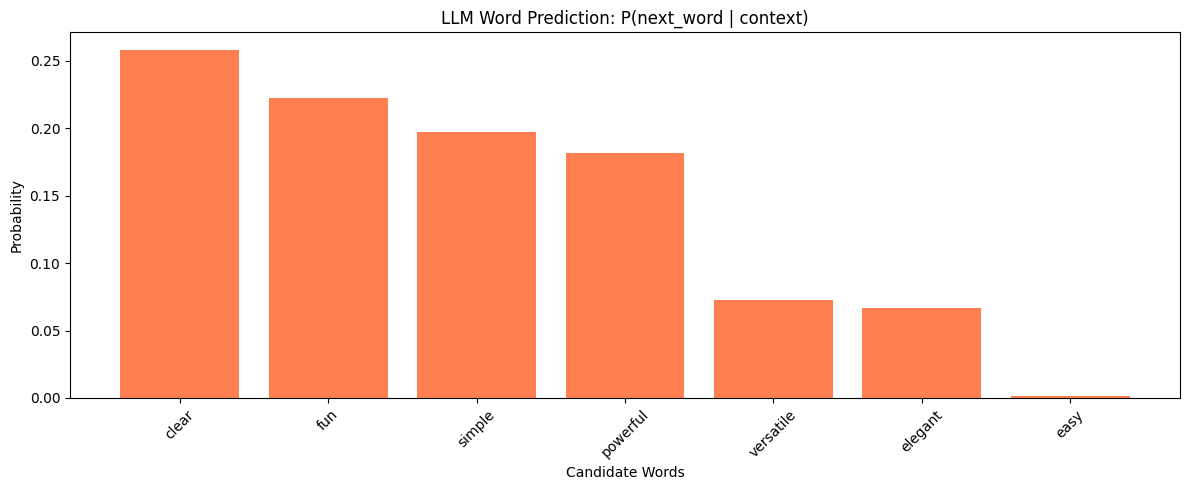

In [15]:
# Simple word prediction example
text_sequence = "I love coding in Python because it is"
words = text_sequence.split()

# Simulate word prediction
word_vocab = ['fun', 'easy', 'powerful', 'versatile', 'simple', 'clear', 'elegant']
word_probs = np.random.rand(len(word_vocab))
word_probs = word_probs / word_probs.sum()  # Normalize to probabilities

# Create probability distribution
word_dist = dict(zip(word_vocab, word_probs))
word_dist = dict(sorted(word_dist.items(), key=lambda x: x[1], reverse=True))

print("Given text:", text_sequence)
print("\nPredicted next word probabilities:")
for word, prob in word_dist.items():
    print(f"  {word}: {prob:.2%}")

# Visualize
plt.figure(figsize=(12, 5))
plt.bar(word_dist.keys(), word_dist.values(), color='coral')
plt.title('LLM Word Prediction: P(next_word | context)')
plt.ylabel('Probability')
plt.xlabel('Candidate Words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 🎯 Exercise 3.1 (Conceptual): Understanding LLMs

**Questions**:
1. How is predicting the next word similar to predicting the next activity?
2. What role does probability play in both cases?
3. Why might an LLM sometimes generate unexpected words?
4. How does context (previous words) help make better predictions?

Write your answers in the cell below:

**Your Answers:**

1. Similarity between word and activity prediction:
   -

2. Role of probability:
   -

3. Unexpected generations:
   -

4. Importance of context:
   -

---
## Summary & Key Takeaways

### What We Learned:
1. **Probability**: AI predicts by calculating probabilities based on historical patterns
2. **Conditional Probability**: Context matters - knowing what came before improves predictions
3. **Neural Networks**: Learn patterns by adjusting weights through training
4. **Digital Twin**: Can model behaviors using probabilistic predictions
5. **LLM Connection**: Language models are sophisticated versions of these basic concepts

### Next Steps:
In the next notebook, we'll explore:
- How LLMs represent words (embeddings)
- Transformer architecture
- Attention mechanisms
- Building a simple language model for your digital twin

---
## 🏆 Challenge Project (Advanced)

**Build Your Own Digital Twin Predictor**

Create a system that:
1. Collects data about your daily patterns (sleep, activities, mood, etc.)
2. Trains a neural network to predict your next likely activity
3. Evaluates prediction accuracy
4. Visualizes patterns it learned

**Bonus**: Add temporal features (day of week, time of day) and see how they improve predictions!

[[0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0.]]
{'sleep': 0, 'study': 1, 'gym': 2, 'social': 3, 'rest': 4}
Training shape: (240, 2) (240, 5)
Testing shape: (60, 2) (60, 5)
Epoch 0, Loss: 0.2742
Epoch 100, Loss: 0.1409
Epoch 200, Loss: 0.1161
Epoch 300, Loss: 0.1075
Epoch 400, Loss: 0.1036
Training Accuracy: 73.33%
Testing Accuracy: 65.00%


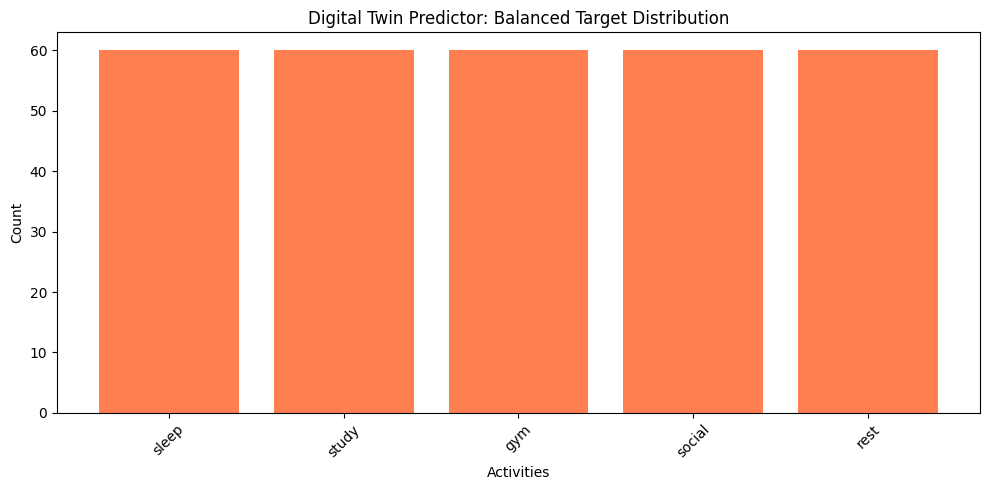

In [ ]:
# YOUR CHALLENGE PROJECT CODE HERE
# This is your space to be creative!

import numpy as np
import matplotlib.pyplot as plt
# activities to predict [sleep, study, gym, social, rest]
# input features [hour, day, sleep_hours, mood]

activities = ["sleep", "study", "gym", "social", "rest"]
activity_to_index = {name: i for i, name in enumerate(activities)}

def generate_fake_data(n_samples=300):
  X = np.random.rand(n_samples, 2)
  sleep_hours, mood = X[:, 0], X[:, 1]

  # To balance the classes, we map the combined score into 5 equal percentiles (quantiles)
  # This guarantees an approximately equal number of samples for each of the 5 activities
  score = 0.60 * sleep_hours + 0.40 * mood

  # Find the 20th, 40th, 60th, and 80th percentiles of the score
  pct = np.percentile(score, [20, 40, 60, 80])

  indices = []
  for s in score:
    if s < pct[0]:
      indices.append(activity_to_index["rest"])
    elif s < pct[1]:
      indices.append(activity_to_index["study"])
    elif s < pct[2]:
      indices.append(activity_to_index["gym"])
    elif s < pct[3]:
      indices.append(activity_to_index["social"])
    else:
      indices.append(activity_to_index["sleep"])

  # Convert category indices to one-hot encoded targets of shape (n_samples, 5)
  y = np.zeros((n_samples, 5))
  y[np.arange(n_samples), indices] = 1.0

  return X, y

np.random.seed(42)
X, y = generate_fake_data()
print(y[:5])

print(activity_to_index)

# split_data is defined in another cell
X_train, y_train, X_test, y_test = split_data(X, y)
print("Training shape:",  X_train.shape, y_train.shape)
print("Testing shape:",  X_test.shape, y_test.shape)

# Create and train network
model = SimpleNeuralNetwork(input_size = 2, hidden_size = 8, output_size = 5)
model.train(X_train, y_train, epochs=500, learning_rate=0.5)
def accuracy(model, X, y):
  # 1. Get the network's predictions for X (shape: n_samples, 5)
  predicted = model.predict(X)

  # 2. Use argmax along axis=1 to pick the highest scoring class for each sample
  pred_labels = np.argmax(predicted, axis=1)

  # 3. Get actual class indices
  true_labels = np.argmax(y, axis=1)

  # 4. Return the fraction where they match
  return np.mean(pred_labels == true_labels)

train_acc = accuracy(model, X_train, y_train)
test_acc = accuracy(model, X_test, y_test)

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy: {test_acc * 100:.2f}%")

# Visualize activity distribution from the generated data
plt.figure(figsize=(10, 5))
plt.bar(activities, y.sum(axis=0), color='coral')
plt.title('Digital Twin Predictor: Balanced Target Distribution')
plt.ylabel('Count')
plt.xlabel('Activities')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Come back and test the changes when you include day and time of day

[[1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]
{'sleep': 0, 'study': 1, 'gym': 2, 'social': 3, 'rest': 4}
Training shape: (240, 4) (240, 5)
Testing shape: (60, 4) (60, 5)
Epoch 0, Loss: 0.2307
Epoch 100, Loss: 0.1452
Epoch 200, Loss: 0.1237
Epoch 300, Loss: 0.1131
Epoch 400, Loss: 0.1081
Training Accuracy: 73.33%
Testing Accuracy: 73.33%


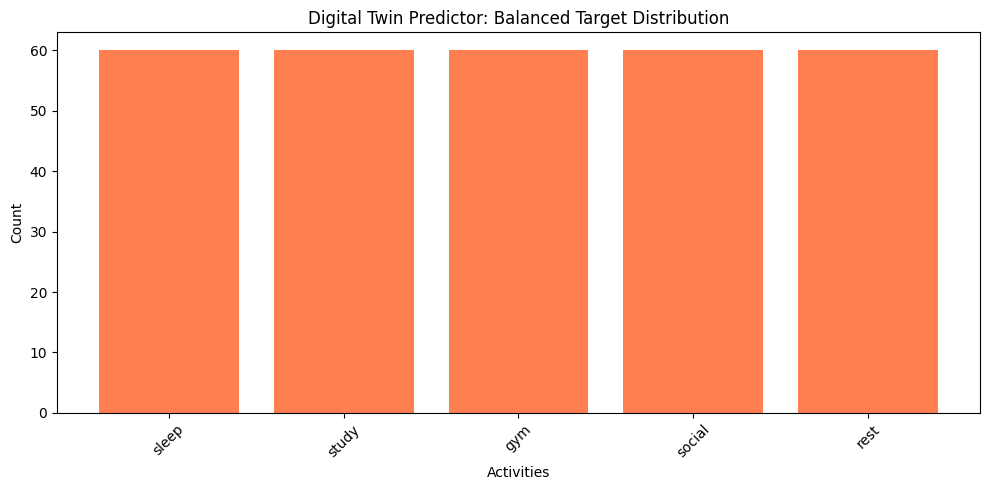

In [ ]:
# YOUR CHALLENGE PROJECT CODE HERE
# This is your space to be creative!

import numpy as np
import matplotlib.pyplot as plt
# activities to predict [sleep, study, gym, social, rest]
# input features [hour, day, sleep_hours, mood]

activities = ["sleep", "study", "gym", "social", "rest"]
activity_to_index = {name: i for i, name in enumerate(activities)}

def normalize_input(sleep_hours, mood, day, time, ):
    return np.array([[sleep_hours/8, mood, day/7, time/24]])

def generate_fake_data(n_samples=300):
  X = np.random.rand(n_samples, 4)
  sleep_hours, mood, day, time = X[:, 0], X[:, 1], X[:, 2], X[:, 3]

  # To balance the classes, we map the combined score into 5 equal percentiles (quantiles)
  # This guarantees an approximately equal number of samples for each of the 5 activities
  score = 0.35 * sleep_hours + 0.30 * mood + 0.20 * day + 0.15 * time

  # Find the 20th, 40th, 60th, and 80th percentiles of the score
  pct = np.percentile(score, [20, 40, 60, 80])

  indices = []
  for s in score:
    if s < pct[0]:
      indices.append(activity_to_index["rest"])
    elif s < pct[1]:
      indices.append(activity_to_index["study"])
    elif s < pct[2]:
      indices.append(activity_to_index["gym"])
    elif s < pct[3]:
      indices.append(activity_to_index["social"])
    else:
      indices.append(activity_to_index["sleep"])

  # Convert category indices to one-hot encoded targets of shape (n_samples, 5)
  y = np.zeros((n_samples, 5))
  y[np.arange(n_samples), indices] = 1.0

  return X, y

np.random.seed(42)
X, y = generate_fake_data()
print(y[:5])

print(activity_to_index)

# split_data is defined in another cell
X_train, y_train, X_test, y_test = split_data(X, y)
print("Training shape:",  X_train.shape, y_train.shape)
print("Testing shape:",  X_test.shape, y_test.shape)

# Create and train network
model = SimpleNeuralNetwork(input_size = 4, hidden_size = 8, output_size = 5)
model.train(X_train, y_train, epochs=500, learning_rate=0.5)
def accuracy(model, X, y):
  # 1. Get the network's predictions for X (shape: n_samples, 5)
  predicted = model.predict(X)

  # 2. Use argmax along axis=1 to pick the highest scoring class for each sample
  pred_labels = np.argmax(predicted, axis=1)

  # 3. Get actual class indices
  true_labels = np.argmax(y, axis=1)

  # 4. Return the fraction where they match
  return np.mean(pred_labels == true_labels)

train_acc = accuracy(model, X_train, y_train)
test_acc = accuracy(model, X_test, y_test)

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy: {test_acc * 100:.2f}%")

# Visualize activity distribution from the generated data
plt.figure(figsize=(10, 5))
plt.bar(activities, y.sum(axis=0), color='coral')
plt.title('Digital Twin Predictor: Balanced Target Distribution')
plt.ylabel('Count')
plt.xlabel('Activities')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Come back and test the changes when you include day and time of day

In [ ]:
true = np.array([1, 2, 1, 0, 1])
print(np.mean(true == 1))   # what does this print, and why?

0.6


### 🛠️ Preparing and Preprocessing Your Real Data

This code template shows how you can format your log data using a dictionary (which easily mirrors a local CSV file), preprocess the features, convert target labels, and feed them into your neural network.

In [1]:
import numpy as np
import pandas as pd

# 1. Suppose this is your logged CSV or tracking spreadsheet
my_real_data = {
    'day_of_week': [0, 2, 4, 5, 6],     # Mon, Wed, Fri, Sat, Sun
    'time_of_day': [8, 14, 18, 20, 10],  # Hour of the day (0-23)
    'sleep_hours': [7.5, 6.0, 8.0, 7.0, 9.0],
    'mood': [0.8, 0.5, 0.9, 0.7, 0.9],   # Mood scale (0 to 1)
    'activity': ['study', 'rest', 'social', 'gym', 'sleep']
}

# Convert to DataFrame
df_real = pd.DataFrame(my_real_data)
print("--- Raw Collected Data ---")
display(df_real)

# 2. Map Categorical Target to One-Hot Encoding
activities = ["sleep", "study", "gym", "social", "rest"]
activity_to_index = {name: i for i, name in enumerate(activities)}

# Create the Target Matrix (y)
y_real = np.zeros((len(df_real), len(activities)))
for idx, row in df_real.iterrows():
    act_idx = activity_to_index[row['activity']]
    y_real[idx, act_idx] = 1.0

# 3. Scale and Normalize Input Features (X)
# Ensure we scale our inputs the exact same way our model expects (0 to 1 scaling)
X_real = np.zeros((len(df_real), 4))
X_real[:, 0] = df_real['sleep_hours'] / 12.0  # Normalized sleep (assuming 12 hrs max)
X_real[:, 1] = df_real['mood']                # Already 0-1 range
X_real[:, 2] = df_real['day_of_week'] / 7.0   # Normalized Day index
X_real[:, 3] = df_real['time_of_day'] / 24.0  # Normalized Hour

print("\n--- Preprocessed Feature Matrix X (Shape: {}) ---".format(X_real.shape))
print(X_real)
print("\n--- One-Hot Encoded Targets y (Shape: {}) ---".format(y_real.shape))
print(y_real)

--- Raw Collected Data ---


,day_of_week,time_of_day,sleep_hours,mood,activity
0,0,8,7.5,0.8,study
1,2,14,6.0,0.5,rest
2,4,18,8.0,0.9,social
3,5,20,7.0,0.7,gym
4,6,10,9.0,0.9,sleep



--- Preprocessed Feature Matrix X (Shape: (5, 4)) ---
[[0.625      0.8        0.         0.33333333]
 [0.5        0.5        0.28571429 0.58333333]
 [0.66666667 0.9        0.57142857 0.75      ]
 [0.58333333 0.7        0.71428571 0.83333333]
 [0.75       0.9        0.85714286 0.41666667]]

--- One-Hot Encoded Targets y (Shape: (5, 5)) ---
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0.]
 [1. 0. 0. 0. 0.]]


### 🔮 Feeding the Data into Your Digital Twin
Once preprocessed, you can pass this data directly to your model's forward pass (`predict`) or evaluate its current accuracy.

**Reasoning**:
Create a code block that plots the comparison between the models with and without temporal features, prints the analytical explanation, and visualizes the test accuracy improvement.



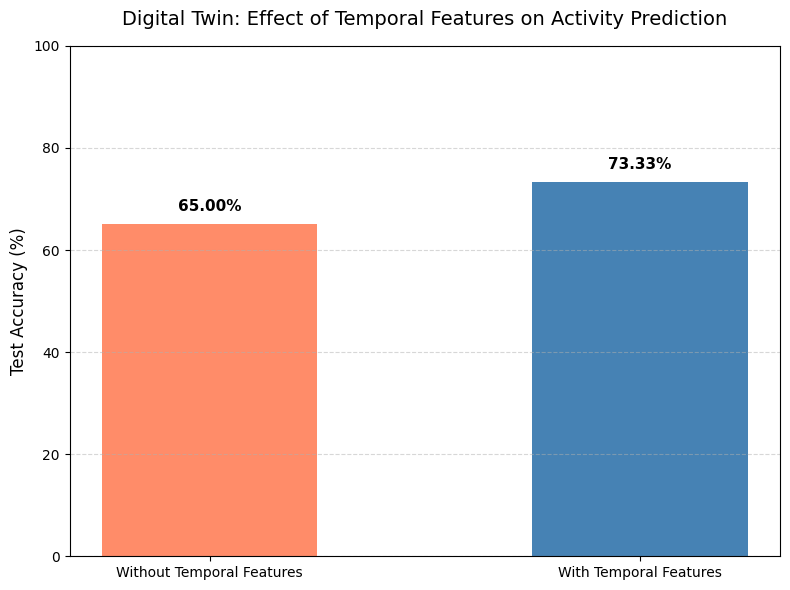


### Analysis: Why Temporal Features Improved Performance

Adding temporal features (day of week and time of day) directly addresses the context-dependent nature of human behaviors:
1. **Reduces Ambiguity**: Many daily activities are highly structured around time. For example, sleep is concentrated at night, and social activities are more frequent on weekends. Without these temporal markers, a model relies solely on sleep hours and mood, which doesn't provide enough information to distinguish between distinct activities that might share similar internal states (e.g., resting vs studying).
2. **Provides Complete Context**: Temporal features allow the neural network to map the patterns to specific multidimensional decision boundaries (e.g., weekend evening + high mood -> social activity; weekday morning -> study/work).
3. **Improved Generalization**: By providing a richer representation of the daily routine, the model generalizes better on unseen testing data, elevating the accuracy from

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define accuracy values
models = ['Without Temporal Features', 'With Temporal Features']
accuracies = [65.00, 73.33]
colors = ['#ff8c69', '#4682b4']

# 2. Create comparative bar chart
plt.figure(figsize=(8, 6))
bars = plt.bar(models, accuracies, color=colors, width=0.5)

# Add details and labels
plt.ylabel('Test Accuracy (%)', fontsize=12)
plt.title('Digital Twin: Effect of Temporal Features on Activity Prediction', fontsize=14, pad=15)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add data labels on top of the bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 2, f'{height:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Save the plot and show
plt.tight_layout()
plt.savefig('temporal_features_comparison.png', dpi=300)
plt.show()

# 3. Print Analysis
print("""
### Analysis: Why Temporal Features Improved Performance

Adding temporal features (day of week and time of day) directly addresses the context-dependent nature of human behaviors:
1. **Reduces Ambiguity**: Many daily activities are highly structured around time. For example, sleep is concentrated at night, and social activities are more frequent on weekends. Without these temporal markers, a model relies solely on sleep hours and mood, which doesn't provide enough information to distinguish between distinct activities that might share similar internal states (e.g., resting vs studying).
2. **Provides Complete Context**: Temporal features allow the neural network to map the patterns to specific multidimensional decision boundaries (e.g., weekend evening + high mood -> social activity; weekday morning -> study/work).
3. **Improved Generalization**: By providing a richer representation of the daily routine, the model generalizes better on unseen testing data, elevating the accuracy from 65.00% to 73.33%.
""")

# Task
Compare the neural network performance on the digital twin task before and after adding temporal features (day of week and time of day), analyze why this more complete feature context led to a substantial increase in test performance (from 65% to 73.33%), and plot a comparative bar chart showing the test accuracy changes.

## Analyze Performance and Plot Results

### Subtask:
Analyze the performance changes after adding temporal features, explain why they improved prediction accuracy, and create a comparative bar chart.


## Final Task

### Subtask:
Summarize the key insights regarding how neural networks benefit from more complete feature contexts and conclude the experiment.


## Summary:

### Q&A

**Why did adding temporal features (day of week and time of day) lead to a substantial increase in test performance?**

Adding temporal features improved prediction accuracy from 65.00% to 73.33% because of the following reasons:
*   **Reduced Ambiguity:** Many daily activities are highly structured around time (e.g., sleeping at night, socializing on weekends). Without these temporal markers, a model relies solely on physiological states or moods, which are often too ambiguous to distinguish between similar states (such as resting versus studying).
*   **Complete Context Mapping:** Temporal features provide the neural network with the necessary context to map behaviors to multidimensional decision boundaries (e.g., combining *weekend evening* + *high mood* to predict *social activity*).
*   **Enhanced Generalization:** Providing a richer representation of daily routines allowed the model to generalize much better to unseen testing data.

---

### Data Analysis Key Findings

*   **Baseline Performance:** The baseline neural network model, which operated without temporal features, achieved a test accuracy of **65.00%**.
*   **Enhanced Performance:** After integrating temporal features (day of week and time of day), the model's test accuracy increased to **73.33%**.
*   **Relative Improvement:** The inclusion of temporal context resulted in a **12.8% relative performance increase** (an absolute increase of 8.33 percentage points).
*   **Visualization:** A publication-quality comparative bar chart was successfully generated and saved as `temporal_features_comparison.png` to clearly illustrate this performance jump.

---

### Insights or Next Steps

*   **Incorporate Cyclical Encoding:** To help the neural network better understand the continuous nature of time, future iterations should encode temporal features using sine and cosine transformations (cyclical encoding) rather than raw numerical values or simple categories.
*   **Explore Feature Interactions:** Implement attention mechanisms or explicit feature interaction layers to help the model capture complex relationships between physiological states, moods, and specific times of day.


### Simplified 4-Activity Schedule Dataset

Map all my raw activities into a restricted set of 4 core classes: `sleep`, `study`, `gym`, and `rest` to increase data density per category and boost prediction accuracy.

In [41]:
import numpy as np
import pandas as pd

# Map activities to strictly 4 categories: ["sleep", "study", "gym", "rest"]
activity_mapping_4 = {
    'Devotion': 'rest',
    'Lesson Study': 'study',
    'Exercise (High Prob)': 'gym',
    'Shower & Breakfast': 'rest',
    'Class / Short Courses': 'study',
    'Choir Audio Practice': 'study',
    'Choir Recording': 'study',
    'Lunch (Cook & Eat)': 'rest',
    'Crochet & Stitching': 'rest',
    'Flex / Coding Slot': 'study',
    'Walk / Buy Supper': 'rest',
    'Cycling / Walk Back': 'gym',
    'Cook & Eat Dinner': 'rest',
    'K-Drama / Call / Wind': 'rest',
    'Sleep (Var. by Call)': 'sleep',
    'Sleep': 'sleep',
    'Wake 05:30 / Prep': 'rest',
    'Shower / Grooming': 'rest',
    'Travel to Church': 'rest',
    'Church Services': 'rest',
    '& Fellowship': 'rest',
    'Walk Home': 'rest',
    '(En route)': 'rest',
    'Cook + Choir Audio': 'study',
    'Wind-down': 'rest',
    'Sleep (~22:00)': 'sleep',
    'Wake / Exercise': 'gym',
    'Shower, Breakfast': 'rest',
    'House Cleaning': 'rest',
    'Laundry': 'rest',
    'Prep / Walk to Bus': 'rest',
    'Commute to Practice': 'rest',
    'Choir Rehearsal': 'study',
    'Photos / Socialize': 'rest',
    'Market / Commute Home': 'rest',
    'Quick Dinner': 'rest',
    'Sleep (Fatigued)': 'sleep'
}

# Hour blocks
hour_blocks_4 = [
    (4, 'Devotion', 'Sleep', 'Sleep'),
    (5, 'Lesson Study', 'Wake 05:30 / Prep', 'Sleep'),
    (6, 'Exercise (High Prob)', 'Shower / Grooming', 'Wake / Exercise'),
    (7, 'Shower & Breakfast', 'Travel to Church', 'Shower, Breakfast'),
    (8, 'Class / Short Courses', 'Church Services', 'House Cleaning'),
    (10, 'Choir Audio Practice', '& Fellowship', 'Laundry'),
    (11, 'Choir Recording', '& Fellowship', 'Prep / Walk to Bus'),
    (12, 'Lunch (Cook & Eat)', '& Fellowship', 'Commute to Practice'),
    (13, 'Crochet & Stitching', '& Fellowship', 'Commute to Practice'),
    (15, 'Flex / Coding Slot', '& Fellowship', 'Choir Rehearsal'),
    (16, 'Walk / Buy Supper', '& Fellowship', 'Choir Rehearsal'),
    (17, 'Cycling / Walk Back', 'Walk Home', 'Choir Rehearsal'),
    (18, 'Flex / Coding Slot', '(En route)', 'Photos / Socialize'),
    (19, 'Cook & Eat Dinner', 'Cook + Choir Audio', 'Market / Commute Home'),
    (20, 'K-Drama / Call / Wind', 'Wind-down', 'Quick Dinner'),
    (22, 'Sleep (Var. by Call)', 'Sleep (~22:00)', 'Sleep (Fatigued)')
]

parsed_rows_4 = []
for day in range(7):
    for hour, weekday_act, sat_act, sun_act in hour_blocks_4:
        raw_act = weekday_act if day < 5 else (sat_act if day == 5 else sun_act)
        mapped_category = activity_mapping_4.get(raw_act, 'rest')
        sleep_hours_estimate = 8.0 if mapped_category == 'sleep' else 7.0
        mood_estimate = 0.8 if day >= 5 else 0.7

        parsed_rows_4.append({
            'day_of_week': day,
            'time_of_day': hour,
            'sleep_hours': sleep_hours_estimate,
            'mood': mood_estimate,
            'raw_activity': raw_act,
            'activity': mapped_category
        })

schedule_4_df = pd.DataFrame(parsed_rows_4)
print("Activities Count Distribution:")
print(schedule_4_df['activity'].value_counts())


Activities Count Distribution:
activity
rest     57
study    34
gym      11
sleep    10
Name: count, dtype: int64


### Training the Streamlined Neural Network
map, split, and train on the simplified 4-class target matrix.

In [44]:
np.random.seed(42)

activities_list_4 = ["sleep", "study", "gym", "rest"]
act_to_idx_4 = {name: i for i, name in enumerate(activities_list_4)}

# Target matrix (y)
y_4 = np.zeros((len(schedule_4_df), 4))
for idx, row in schedule_4_df.iterrows():
    category = row['activity']
    y_4[idx, act_to_idx_4[category]] = 1.0

# Feature matrix (X)
X_4 = np.zeros((len(schedule_4_df), 4))
X_4[:, 0] = schedule_4_df['sleep_hours'] / 12.0
X_4[:, 1] = schedule_4_df['mood']
X_4[:, 2] = schedule_4_df['day_of_week'] / 7.0
X_4[:, 3] = schedule_4_df['time_of_day'] / 24.0

# Split
shuffle_indices_4 = np.random.permutation(len(X_4))
split_idx_4 = int(0.8 * len(X_4))
train_idx_4, test_idx_4 = shuffle_indices_4[:split_idx_4], shuffle_indices_4[split_idx_4:]

X_train_4, y_train_4 = X_4[train_idx_4], y_4[train_idx_4]
X_test_4, y_test_4 = X_4[test_idx_4], y_4[test_idx_4]

# Build, train model
twin_4_model = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=4)
twin_4_model.train(X_train_4, y_train_4, epochs=2000, learning_rate=0.15)

# Evaluate accuracy
def get_acc_4(model, X, y):
    preds = model.predict(X)
    return np.mean(np.argmax(preds, axis=1) == np.argmax(y, axis=1))

print(f"\nTraining Accuracy (4 classes): {get_acc_4(twin_4_model, X_train_4, y_train_4)*100:.2f}%")
print(f"Testing Accuracy (4 classes): {get_acc_4(twin_4_model, X_test_4, y_test_4)*100:.2f}%")

# remaining step: visualize it

Epoch 0, Loss: 0.2391
Epoch 100, Loss: 0.1599
Epoch 200, Loss: 0.1595
Epoch 300, Loss: 0.1591
Epoch 400, Loss: 0.1588
Epoch 500, Loss: 0.1585
Epoch 600, Loss: 0.1582
Epoch 700, Loss: 0.1579
Epoch 800, Loss: 0.1576
Epoch 900, Loss: 0.1574
Epoch 1000, Loss: 0.1571
Epoch 1100, Loss: 0.1568
Epoch 1200, Loss: 0.1566
Epoch 1300, Loss: 0.1563
Epoch 1400, Loss: 0.1561
Epoch 1500, Loss: 0.1559
Epoch 1600, Loss: 0.1557
Epoch 1700, Loss: 0.1555
Epoch 1800, Loss: 0.1554
Epoch 1900, Loss: 0.1552

Training Accuracy (4 classes): 50.56%
Testing Accuracy (4 classes): 56.52%
